In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [ ]:
df = pd.read_csv('Agriculture_commodities_dataset.csv')
df.head()

,APMC,Commodity,Year,Month,arrivals_in_qtl,min_price,max_price,modal_price,date,district_name,state_name
0,Ahmednagar,Bajri,2015,April,79,1406,1538,1463,2015-04,Ahmadnagar,Maharashtra
1,Ahmednagar,Bajri,2016,April,106,1788,1925,1875,2016-04,Ahmadnagar,Maharashtra
2,Ahmednagar,Wheat(Husked),2015,April,1253,1572,1890,1731,2015-04,Ahmadnagar,Maharashtra
3,Ahmednagar,Wheat(Husked),2016,April,387,1750,2220,1999,2016-04,Ahmadnagar,Maharashtra
4,Ahmednagar,Sorgum(Jawar),2015,April,3825,1600,2200,1900,2015-04,Ahmadnagar,Maharashtra


In [ ]:
df.shape

(62429, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62429 entries, 0 to 62428
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   APMC             62429 non-null  object
 1   Commodity        62429 non-null  object
 2   Year             62429 non-null  int64 
 3   Month            62429 non-null  object
 4   arrivals_in_qtl  62429 non-null  int64 
 5   min_price        62429 non-null  int64 
 6   max_price        62429 non-null  int64 
 7   modal_price      62429 non-null  int64 
 8   date             62429 non-null  object
 9   district_name    62429 non-null  object
 10  state_name       62429 non-null  object
dtypes: int64(5), object(6)
memory usage: 5.2+ MB


In [ ]:
df.isna().sum().sum()

0

In [ ]:
df.describe()

,Year,arrivals_in_qtl,min_price,max_price,modal_price
count,62429.000000,6.242900e+04,6.242900e+04,6.242900e+04,62429.000000
mean,2015.337503,6.043088e+03,2.945228e+03,3.688814e+03,3296.003989
std,0.690451,3.470331e+04,1.318396e+04,7.662962e+03,3607.792534
min,2014.000000,1.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2015.000000,3.800000e+01,1.250000e+03,1.600000e+03,1450.000000
50%,2015.000000,2.110000e+02,1.976000e+03,2.797000e+03,2425.000000
75%,2016.000000,1.364000e+03,3.900000e+03,4.647000e+03,4257.000000
max,2016.000000,1.450254e+06,3.153038e+06,1.600090e+06,142344.000000


In [ ]:
df.nunique()

,0
APMC,349
Commodity,352
Year,3
Month,12
arrivals_in_qtl,11169
min_price,8503
max_price,9739
modal_price,9327
date,27
district_name,33


In [ ]:
df

,APMC,Commodity,Year,Month,arrivals_in_qtl,min_price,max_price,modal_price,date,district_name,state_name
0,Ahmednagar,Bajri,2015,April,79,1406,1538,1463,2015-04,Ahmadnagar,Maharashtra
1,Ahmednagar,Bajri,2016,April,106,1788,1925,1875,2016-04,Ahmadnagar,Maharashtra
2,Ahmednagar,Wheat(Husked),2015,April,1253,1572,1890,1731,2015-04,Ahmadnagar,Maharashtra
3,Ahmednagar,Wheat(Husked),2016,April,387,1750,2220,1999,2016-04,Ahmadnagar,Maharashtra
4,Ahmednagar,Sorgum(Jawar),2015,April,3825,1600,2200,1900,2015-04,Ahmadnagar,Maharashtra
...,...,...,...,...,...,...,...,...,...,...,...
62424,Shrigonda,GRAM,2016,November,586,5700,6367,6200,2016-11,Ahmadnagar,Maharashtra
62425,Shrigonda,GREEN GRAM,2016,November,2,5000,5000,5000,2016-11,Ahmadnagar,Maharashtra
62426,Shrigonda,BLACK GRAM,2016,November,46,4700,6933,6400,2016-11,Ahmadnagar,Maharashtra
62427,Shrigonda,SOYBEAN,2016,November,166,2583,2708,2633,2016-11,Ahmadnagar,Maharashtra


In [ ]:
df.duplicated().sum()

0

In [ ]:
df.drop('date',axis=1,inplace=True)

In [ ]:
df.head()

,APMC,Commodity,Year,Month,arrivals_in_qtl,min_price,max_price,modal_price,district_name,state_name
0,Ahmednagar,Bajri,2015,April,79,1406,1538,1463,Ahmadnagar,Maharashtra
1,Ahmednagar,Bajri,2016,April,106,1788,1925,1875,Ahmadnagar,Maharashtra
2,Ahmednagar,Wheat(Husked),2015,April,1253,1572,1890,1731,Ahmadnagar,Maharashtra
3,Ahmednagar,Wheat(Husked),2016,April,387,1750,2220,1999,Ahmadnagar,Maharashtra
4,Ahmednagar,Sorgum(Jawar),2015,April,3825,1600,2200,1900,Ahmadnagar,Maharashtra


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [ ]:
for i in df.columns:
  if df[i].dtype == 'object':
    df[i] = le.fit_transform(df[i])

Index(['APMC', 'Commodity', 'Year', 'Month', 'arrivals_in_qtl', 'min_price',
       'max_price', 'modal_price', 'district_name', 'state_name'],
      dtype='object')


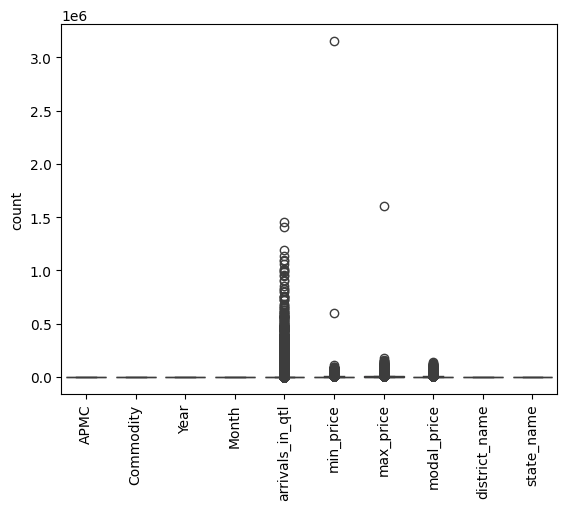

In [ ]:
dd = df.select_dtypes(include=['int64']).columns
print(dd)
sns.boxplot(df[dd])
plt.xticks(rotation='vertical')
plt.ylabel("count")
plt.show()

In [ ]:
outliers_list = ['arrivals_in_qtl','min_price','max_price','modal_price']
for i in outliers_list:
  q1 = df[i].quantile(0.25)
  q3 = df[i].quantile(0.75)
  iqr = q3-q1
  df = df[(df[i]>q1-1.5*iqr) & (df[i]<q3+1.5*iqr)]

NameError: name 'df' is not defined

In [ ]:
df.shape

(48813, 10)

In [ ]:
X = df.drop('modal_price', axis=1)
y = df['modal_price']

In [ ]:
X

,APMC,Commodity,Year,Month,arrivals_in_qtl,min_price,max_price,district_name,state_name
0,4,24,2015,0,79,1406,1538,0,0
1,4,24,2016,0,106,1788,1925,0,0
2,4,348,2015,0,1253,1572,1890,0,0
3,4,348,2016,0,387,1750,2220,0,0
5,4,310,2016,0,2093,1695,2454,0,0
...,...,...,...,...,...,...,...,...,...
62424,298,114,2016,9,586,5700,6367,0,0
62425,298,117,2016,9,2,5000,5000,0,0
62426,298,19,2016,9,46,4700,6933,0,0
62427,298,287,2016,9,166,2583,2708,0,0


In [ ]:
y

,modal_price
0,1463
1,1875
2,1731
3,1999
5,2119
...,...
62424,6200
62425,5000
62426,6400
62427,2633


In [ ]:
x_test,x_train,y_test,y_train = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [ ]:
df.head()

,APMC,Commodity,Year,Month,arrivals_in_qtl,min_price,max_price,modal_price,district_name,state_name
0,4,24,2015,0,79,1406,1538,1463,0,0
1,4,24,2016,0,106,1788,1925,1875,0,0
2,4,348,2015,0,1253,1572,1890,1731,0,0
3,4,348,2016,0,387,1750,2220,1999,0,0
5,4,310,2016,0,2093,1695,2454,2119,0,0


In [ ]:
x_train

,APMC,Commodity,Year,Month,arrivals_in_qtl,min_price,max_price,district_name,state_name
18367,135,259,2015,6,10,6000,6000,11,0
18857,113,315,2015,0,94,1205,1220,12,0
22132,118,67,2015,8,10,2925,2925,13,0
14247,197,310,2016,8,301,1167,1364,6,0
45792,257,335,2015,11,3006,621,1011,23,0
...,...,...,...,...,...,...,...,...,...
62231,11,186,2016,9,143,1392,1567,0,0
27384,211,259,2015,0,3038,5315,6632,17,0
24100,157,126,2016,11,31,800,1250,14,0
37480,325,250,2015,3,1,750,900,21,0


In [ ]:
predictions = model.predict(x_test)

In [ ]:
from sklearn.metrics import r2_score
r2_score(y_test,predictions)

0.9867136872858511

In [ ]:
y_train

,modal_price
18367,6000
18857,1210
22132,2925
14247,1287
45792,879
...,...
62231,1500
27384,5974
24100,950
37480,800


In [ ]:
model.predict([[135,259,	2015	,6	,10,	6000,	6000,	11,	0]])

/usr/local/lib/python3.10/dist-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([6044.63764509])